In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
#from tqdm import tqdm_notebook as tqdm
from tqdm.auto import tqdm
import torch
import time

#from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import lqproblem
import optimiser_lqproblem as optimiser_lqproblem
from math import factorial
import pickle

/nfs/home/alifa/myenv/lib/python3.12/site-packages/torch/__init__.py:1305: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at /pytorch/torch/csrc/tensor/python_tensor.cpp:434.)
  _C._set_default_tensor_type(t)


In [2]:
with open(f'experiment_params.pkl', 'rb') as f:
    params = pickle.load(f)
    f.close()

env = lqproblem.environment(**params)
env_hjb = lqproblem.environment(**params)
env_hjb_sig = lqproblem.environment(**params)

In [3]:
max_order_x_list = [1, 2, 3, 4]
max_order_F_list = [0, 1, 2, 3]
nsims = 1000
dim = env.dim
nsims_small = nsims
nsim = 0 

with open(f'experiment_results_{nsims}_sims.pkl', 'rb') as f:
    sim_list = pickle.load(f)
    f.close()

with open(f'experiment_results_hjb_{nsims}_sims.pkl', 'rb') as f:
    nu_hjb = pickle.load(f)
    f.close()

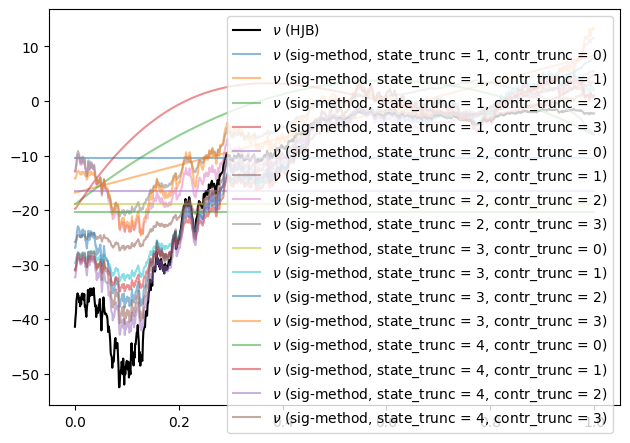

In [9]:
plt.plot(env.timesteps, nu_hjb[:,nsim], label=r'$\nu$ (HJB)', color='black')

for max_order_x in max_order_x_list:
    for max_order_F in max_order_F_list:
        nu = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x) and (sims['max_order_F'] == max_order_F)][0]
        plt.plot(env.timesteps, nu[:,nsim], label=rf'$\nu$ (sig-method, state_trunc = {max_order_x}, contr_trunc = {max_order_F})',
                         alpha=0.5)
        # if max_order_x >= 4 and max_order_F >= 2:
        #         nu = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x) and (sims['max_order_F'] == max_order_F)][0]
        #         plt.plot(env.timesteps, nu[:,nsim], label=rf'$\nu$ (sig-method, state_trunc = {max_order_x}, contr_trunc = {max_order_F})',
        #                  alpha=0.5)

plt.legend()
plt.tight_layout()
plt.show()

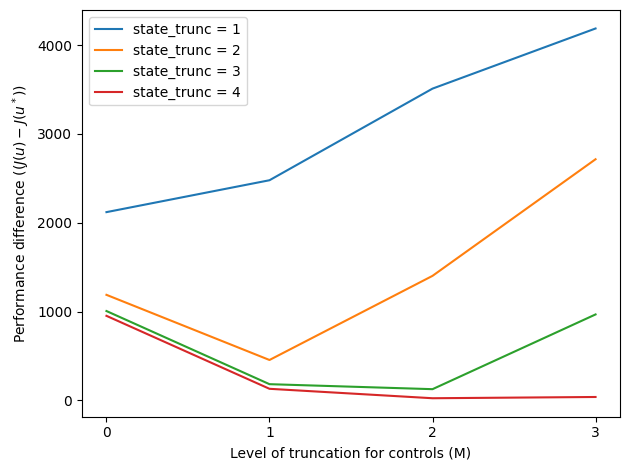

In [5]:
for max_order_x in max_order_x_list:
    perform_diff = [experiment['outperformance'] for experiment in sim_list if experiment['max_order_x']==max_order_x]
    plt.plot(max_order_F_list, perform_diff, label=f'state_trunc = {max_order_x}')

plt.xticks(ticks=max_order_F_list)
plt.xlabel(r'Level of truncation for controls (M)')
plt.ylabel(r'Performance difference ($(J(u) - J(u^*)$)')
plt.legend()
plt.tight_layout()
plt.show()

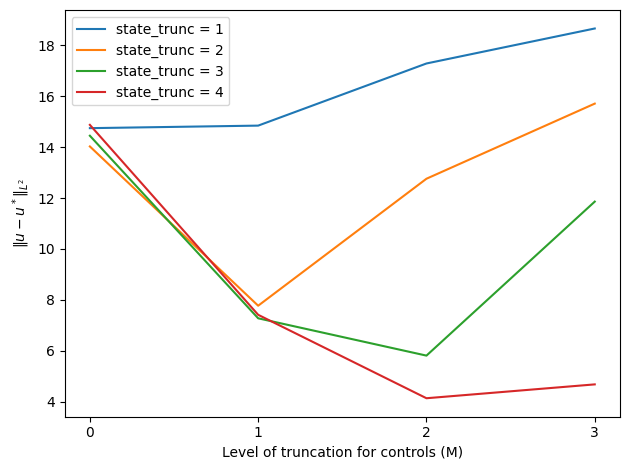

In [6]:
for max_order_x in max_order_x_list:
    perform_diff = [experiment['nu_rmse'] for experiment in sim_list if experiment['max_order_x']==max_order_x]
    plt.plot(max_order_F_list, perform_diff, label=f'state_trunc = {max_order_x}')

plt.xticks(ticks=max_order_F_list)
plt.xlabel(r'Level of truncation for controls (M)')
plt.ylabel(r'$\|u - u^*\|_{L^2}$')
plt.legend()
plt.tight_layout()
plt.show()

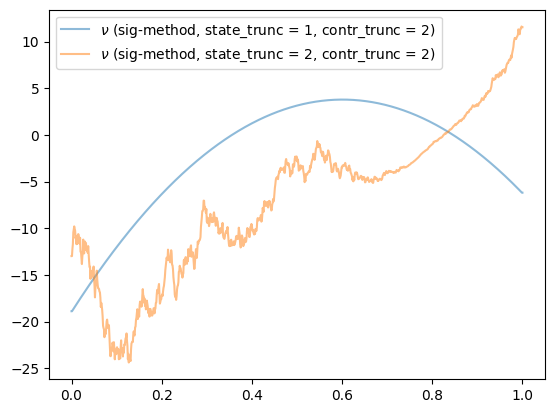

In [11]:
max_order_x_1 = 1
max_order_x_2 = 2
max_order_F_0 = 2

nu_1 = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x_1) and (sims['max_order_F'] == max_order_F_0)][0]
nu_2 = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x_2) and (sims['max_order_F'] == max_order_F_0)][0]

plt.plot(env.timesteps, nu_1[:,nsim], label=rf'$\nu$ (sig-method, state_trunc = {max_order_x_1}, contr_trunc = {max_order_F_0})',
        alpha=0.5)
plt.plot(env.timesteps, nu_2[:,nsim], label=rf'$\nu$ (sig-method, state_trunc = {max_order_x_2}, contr_trunc = {max_order_F_0})',
        alpha=0.5)
plt.legend()
plt.show()

In [13]:
filename_1 = f'lev_control_{max_order_F_0}_lev_state_{max_order_x_1}_analytical'
filename_2 = f'lev_control_{max_order_F_0}_lev_state_{max_order_x_2}_analytical'
F_list = []

for filename in [filename_1, filename_2]:
    with open(f'F_optimised_lqproblem_{filename}.pkl', 'rb') as f:
        F = pickle.load(f)
        f.close()
    F_list.append(F)

In [16]:
F_list[0]

array([ -18.9,   75.6,    0. , -126. ,    0. ,    0. ,    0. ])

In [17]:
sim_list

[{'max_order_x': 1,
  'max_order_F': 0,
  'nu_sims': array([[-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         ...,
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5],
         [-10.5, -10.5, -10.5, ..., -10.5, -10.5, -10.5]],
        shape=(1001, 1000)),
  'performance': np.float64(2574.3658713426657),
  'outperformance': np.float64(2119.001689591187),
  'nu_rmse': np.float64(14.744033557112038)},
 {'max_order_x': 1,
  'max_order_F': 1,
  'nu_sims': array([[-16.8       , -16.8       , -16.8       , ..., -16.8       ,
          -16.8       , -16.8       ],
         [-16.8       , -16.8       , -16.8       , ..., -16.8       ,
          -16.8       , -16.8       ],
         [-16.7748    , -16.7748    , -16.7748    , ..., -16.7748    ,
          -16.7748    , -16.7748    ],
         ...,
         [  8.32